## 02b Rainfall Features (NOAA CPC Unified, observed)

#### Purpose
We give every policy-year two kinds of rainfall information, both known at the **start** of the policy-year:
- **Static** (one value per place): how rainy the place is in the long run, over 1981–2013, before our first policy-year: the average annual rainfall, the average wettest day, and the **100-year 1-day rainfall**.
- **Dated** (per place and start date): how much rain fell **before** the start: the last 90 days, the last 365 days as % of normal, the wettest day and wettest 3 days of the last year, and the days with 50+ mm in the last 3 years.

Rain **during** the policy-year is part of the outcome, so it is never a feature. Every window ends the day before the start.

#### The data
NOAA's Climate Prediction Center grids the daily totals of **rain gauges**, so these are real days (Harvey is in it). NOAA PSL publishes one NetCDF file per year:

| Product | Grid | Years | Used for |
|---|---|---|---|
| CPC US Unified V1.0 | 0.25° (about 28 km) | 1948–2006 | Mainland US |
| CPC US Unified RT (real-time) | 0.25° | 2007 onwards | Mainland US |
| CPC Global Unified | 0.5° (about 55 km) | 1979 onwards | Alaska, Hawaii, Puerto Rico, the Virgin Islands and the Pacific territories, where the US grid has no values |

#### Steps:
- Download every year we need (1981–2024), unchanged, into `data/raw/cpc_precip/`
- Give each policy location the nearest grid cell with gauge values
- Read each year once and keep the daily values at our cells only
- Check the data: complete years, the 2007 switch to the real-time product, known places, Harvey
- Build the static features (with a GEV fit for the 100-year rainfall)
- Build the dated features for every start date from January 2014 to August 2024

#### Outputs
- `data/processed/precip_locations.parquet`: policy location (0.1°) → grid cell
- `data/processed/precip_climate.parquet`: static features per cell
- `data/processed/precip_daily/<year>.parquet`: dated features per cell and start date

### Section 0. Setup

#### 0.1 Imports and paths
The functions are in `src/precip.py`; use `help(function_name)` for their documentation.

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from src.paths import INTERIM, PROCESSED, RAW, REPORTS, ensure_dirs
from src.db import connect
from src.precip import (SOURCES, annual_from_matrix, climate_summary, cpc_url, dated_windows, download,
                        gather_year, local_path, map_locations, save_daily, valid_mask)

ensure_dirs()

#### 0.2 Settings
- **Climate years 1981–2013:** 33 years, all before our first policy-year, for the static features.
- **Daily years 2011–2024:** the dated windows reach 3 years back from the first start (January 2014), up to the last start (August 2024).
- **Start dates:** the first and last start come from the modeling population (notebook 04).

In [2]:
CLIMATE_YEARS = list(range(1981, 2014))     # static features: 1981-2013
DAILY_YEARS = list(range(2011, 2025))       # dated windows: 3 years before the first start, up to 2024
ALL_YEARS = sorted(set(CLIMATE_YEARS) | set(DAILY_YEARS))
REF_YEAR = 2017                             # year used to find the cells that have gauge values
RETURN_PERIOD, MIN_YEARS = 100, 20          # 100-year rainfall; fewer complete years -> NULL
US_MAX_KM, GLOBAL_MAX_KM = 25, 60           # farthest a location may be from its cell's centre

RAW_CPC = RAW / "cpc_precip"                # downloaded files, kept unchanged
WORK = INTERIM / "precip"                   # per-year intermediate results (so a stopped run resumes)
DAILY_OUT = PROCESSED / "precip_daily"
for p in (RAW_CPC, WORK / "annual", WORK / "cells", DAILY_OUT):
    p.mkdir(parents=True, exist_ok=True)

con = connect(db_path=None, memory_limit="6GB")
START_FROM, START_TO = con.execute(f'''
    SELECT MIN(period_start), MAX(period_start)
    FROM read_parquet('{PROCESSED / "modeling_population.parquet"}')''').fetchall()[0]
print("start dates in the modelling population:", START_FROM, "to", START_TO)

start dates in the modelling population: 2014-01-01 to 2024-08-31


### Section 1. Download

#### 1.1 Every year of both grids
About 9 MB per US year and 60 MB per global year, about **3 GB** in total. Files already there are skipped, so the cell can be rerun. US years up to 2006 come from V1.0, and from 2007 from the real-time (RT) folder.

In [3]:
# Step 1.1 Download (skips files already downloaded)
t0 = time.time()
with requests.Session() as session:
    for year in ALL_YEARS:
        for source in SOURCES:
            if not local_path(RAW_CPC, source, year).exists():
                download(RAW_CPC, source, year, session=session)
                print(f"{source} {year} downloaded")
files = pd.DataFrame([{"source": s, "year": y, "file": local_path(RAW_CPC, s, y).name,
                       "mb": round(local_path(RAW_CPC, s, y).stat().st_size / 1e6, 1)}
                      for s in SOURCES for y in ALL_YEARS])
print(f"{len(files)} files, {files['mb'].sum() / 1000:.1f} GB, {time.time() - t0:.0f} s")
files.pivot(index="year", columns="source", values="mb").T

us 1981 downloaded
global 1981 downloaded
us 1982 downloaded
global 1982 downloaded
us 1983 downloaded
global 1983 downloaded
us 1984 downloaded
global 1984 downloaded
us 1985 downloaded
global 1985 downloaded
us 1986 downloaded
global 1986 downloaded
us 1987 downloaded
global 1987 downloaded
us 1988 downloaded
global 1988 downloaded
us 1989 downloaded
global 1989 downloaded
us 1990 downloaded
global 1990 downloaded
us 1991 downloaded
global 1991 downloaded
us 1992 downloaded
global 1992 downloaded
us 1993 downloaded
global 1993 downloaded
us 1994 downloaded
global 1994 downloaded
us 1995 downloaded
global 1995 downloaded
us 1996 downloaded
global 1996 downloaded
us 1997 downloaded
global 1997 downloaded
us 1998 downloaded
global 1998 downloaded
us 1999 downloaded
global 1999 downloaded
us 2000 downloaded
global 2000 downloaded
us 2001 downloaded
global 2001 downloaded
us 2002 downloaded
global 2002 downloaded
us 2003 downloaded
global 2003 downloaded
us 2004 downloaded
global 2004 dow

year,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
source,,,,,,,,,,,,,,,,,,,,,
global,66.5,64.0,64.0,62.9,61.9,64.6,62.7,64.0,65.1,61.4,...,62.9,57.9,60.2,58.9,59.8,59.1,59.9,66.3,64.5,66.1
us,9.9,11.1,11.0,10.8,10.5,10.7,10.3,9.8,10.1,10.4,...,10.8,9.7,10.8,9.3,10.5,10.3,10.1,10.4,10.1,10.0


### Section 2. Policy locations → grid cells

#### 2.1 Cells with gauge values
A cell has values if it has a value on at least 90% of the days of 2017. Cells over the sea, or without gauges, have none.

In [4]:
# Step 2.1 Cells with gauge values, per grid
grids = {s: valid_mask(local_path(RAW_CPC, s, REF_YEAR)) for s in SOURCES}
for s, (lat, lon, mask) in grids.items():
    print(f"{s:6s}: {len(lat)} x {len(lon)} cells, lat {lat.min()}..{lat.max()}, lon {lon.min()}..{lon.max()}, "
          f"with values: {mask.sum():,}")

us    : 120 x 300 cells, lat 20.125..49.875, lon 230.125..304.875, with values: 13,626
global: 360 x 720 cells, lat -89.75..89.75, lon 0.25..359.75, with values: 93,059


#### 2.2 Map each location to its cell
Each distinct policy location (rounded to 0.1° by FEMA) gets the **nearest cell with gauge values**: on the US grid if the location is inside it and a cell is within 25 km, otherwise on the global grid within 60 km. A coastal location whose own cell is sea gets the nearest land cell. `dist_km` is the distance to the cell's centre.

In [5]:
# Step 2.2 Location -> cell
locations = con.sql(f'''
    SELECT CAST(latitude AS DOUBLE) AS latitude, CAST(longitude AS DOUBLE) AS longitude,
           MODE(propertyState) AS state, COUNT(*) AS policy_terms
    FROM read_parquet('{PROCESSED / "policies_clean"}/**/*.parquet', hive_partitioning = true)
    WHERE latitude IS NOT NULL AND longitude IS NOT NULL
    GROUP BY 1, 2
''').df()
locations, cells = map_locations(locations, grids, us_max_km=US_MAX_KM, global_max_km=GLOBAL_MAX_KM)
locations.to_parquet(PROCESSED / "precip_locations.parquet", index=False)
cells.to_parquet(WORK / "cells.parquet", index=False)

print(f"{len(locations):,} locations -> {len(cells):,} cells "
      f"({(cells['source'] == 'us').sum():,} US, {(cells['source'] == 'global').sum():,} global)")
summary = locations.assign(source=locations["source"].fillna("(no cell)")).groupby("source").agg(
    locations=("latitude", "size"), policy_terms=("policy_terms", "sum"), median_km=("dist_km", "median"), max_km=("dist_km", "max"))
summary["pct_policy_terms"] = (100 * summary["policy_terms"] / summary["policy_terms"].sum()).round(2)
summary

41,470 locations -> 9,853 cells (9,682 US, 171 global)


,locations,policy_terms,median_km,max_km,pct_policy_terms
source,,,,,
(no cell),23,291498,NaN,NaN,0.39
global,571,773645,18.2,56.0,1.04
us,40876,73602994,10.2,24.8,98.57


In [6]:
# Step 2.3 Which states use the global grid, and which locations have no cell?
display(locations[locations["source"] == "global"].groupby("state")["policy_terms"].sum().sort_values(ascending=False).head(10))
locations[locations["source"].isna()].groupby("state")["policy_terms"].sum().sort_values(ascending=False).head(10)

state
PR    311924
HI    296184
AK     47704
FL     41778
TX     36936
VI     22901
NC     12319
GU      3646
MP       104
ME        27
Name: policy_terms, dtype: int64

state
FL    290816
AS       627
MP        40
MA        11
NC         2
CO         1
WV         1
Name: policy_terms, dtype: int64

### Section 3. Read each year at our cells

#### 3.1 Yearly loop
For each year we read both files once, keep only our cells, and save:
- the **annual total and wettest day** per cell (every year, for the static features and checks);
- the **daily values** per cell (2011–2024 only, for the dated windows).

Years already saved are skipped, so a stopped run restarts where it stopped. A cell with values on fewer than 95% of a year's days gets no annual value for that year.

In [7]:
# Step 3.1 Yearly loop (resumable)
t_start = time.time()
for year in ALL_YEARS:
    annual_file, cells_file = WORK / "annual" / f"{year}.parquet", WORK / "cells" / f"{year}.npz"
    if annual_file.exists() and (year not in DAILY_YEARS or cells_file.exists()):
        continue
    t0 = time.time()
    dates, x = gather_year({s: local_path(RAW_CPC, s, year) for s in SOURCES}, cells)
    annual_from_matrix(dates, x).to_parquet(annual_file, index=False)
    if year in DAILY_YEARS:
        np.savez_compressed(cells_file, dates=dates, x=x)
    print(f"{year}: {len(dates)} days, {time.time() - t0:.0f} s")
print(f"done in {(time.time() - t_start) / 60:.1f} min")

1981: 365 days, 1 s
1982: 365 days, 1 s
1983: 365 days, 1 s
1984: 366 days, 1 s
1985: 365 days, 1 s
1986: 365 days, 1 s
1987: 365 days, 1 s
1988: 366 days, 1 s
1989: 365 days, 1 s
1990: 365 days, 1 s
1991: 365 days, 1 s
1992: 366 days, 1 s
1993: 365 days, 1 s
1994: 365 days, 1 s
1995: 365 days, 1 s
1996: 366 days, 1 s
1997: 365 days, 1 s
1998: 365 days, 1 s
1999: 365 days, 1 s
2000: 366 days, 1 s
2001: 365 days, 1 s
2002: 365 days, 1 s
2003: 365 days, 1 s
2004: 366 days, 1 s
2005: 365 days, 1 s
2006: 365 days, 1 s
2007: 365 days, 1 s
2008: 366 days, 1 s
2009: 365 days, 1 s
2010: 365 days, 1 s
2011: 365 days, 1 s
2012: 366 days, 1 s
2013: 365 days, 1 s
2014: 365 days, 1 s
2015: 365 days, 1 s
2016: 366 days, 1 s
2017: 365 days, 1 s
2018: 365 days, 1 s
2019: 365 days, 1 s
2020: 366 days, 1 s
2021: 365 days, 1 s
2022: 365 days, 1 s
2023: 365 days, 1 s
2024: 366 days, 1 s
done in 0.9 min


### Section 4. Checks

In [8]:
# Step 4.1 Every year is there, with a full year of days and values for most cells
annual = pd.read_parquet(WORK / "annual").merge(cells[["cell_id", "source"]], on="cell_id")
check = annual.groupby(["year", "source"]).agg(cells=("cell_id", "size"),
                                               pct_cells_with_value=("annual_mm", lambda s: round(100 * s.notna().mean(), 1)),
                                               median_annual_mm=("annual_mm", "median")).unstack("source")
print("years missing:", sorted(set(ALL_YEARS) - set(annual["year"])) or "none")
check

years missing: none


cells       pct_cells_with_value        median_annual_mm             
source global    us               global     us           global           us
year                                                                         
1981      171  9682                100.0  100.0       695.525771   903.736644
1982      171  9682                100.0  100.0       779.093408   947.478767
1983      171  9682                100.0  100.0       673.784589   945.678767
1984      171  9682                100.0  100.0       687.398031   916.831882
1985      171  9682                100.0  100.0       763.366725   930.458519
1986      171  9682                100.0  100.0       787.399913   940.343836
1987      171  9682                100.0  100.0       764.061387   856.190154
1988      171  9682                100.0  100.0       641.833632   712.728633
1989      171  9682                100.0  100.0       591.142509   783.403425
1990      171  9682                100.0  100.0       752.530565   987.142038
1991      171  9682                100.0  100.0       622.733562   897.813057
1992      171  9682                100.0  100.0       538.956370   924.153560
1993      171  9682                100.0  100.0       599.904495   982.821918
1994      171  9682                100.0  100.0       552.807577   861.555137
1995      171  9682                100.0  100.0       486.559161   920.228767
1996      171  9682                100.0  100.0       457.224471   968.044057
1997      171  9682                100.0  100.0       542.564341   880.558091
1998      171  9682                100.0  100.0       578.881635   974.321533
1999      171  9682                100.0  100.0       559.826584   810.633005
2000      171  9682                100.0  100.0       544.660391   836.951588
2001      171  9682                100.0  100.0       639.522646   814.786173
2002      171  9682                100.0  100.0       755.840925   852.893065
2003      171  9682                100.0  100.0       808.532620   811.877140
2004      171  9682                100.0  100.0       851.614071   949.250000
2005      171  9682                100.0  100.0       676.002825   787.309932
2006      171  9682                100.0  100.0       665.661986   831.021661
2007      171  9682                 87.7  100.0       520.328597   890.870579
2008      171  9682                 87.7  100.0       637.940531   967.620774
2009      171  9682                 87.7  100.0       546.446340   927.034375
2010      171  9682                 87.7  100.0       604.301605   922.523245
2011      171  9682                 87.7  100.0       553.010873   836.116781
2012      171  9682                100.0  100.0       689.180840   767.239327
2013      171  9682                100.0  100.0       728.919949   898.639983
2014      171  9682                100.0  100.0       682.874529   891.837885
2015      171  9682                100.0  100.0       706.933733   963.804238
2016      171  9682                100.0  100.0       695.155012   901.419869
2017      171  9682                100.0  100.0       691.030137   952.103125
2018      171  9682                100.0  100.0       703.161173   984.693236
2019      171  9682                100.0  100.0       670.428425  1027.409461
2020      171  9682                100.0  100.0       704.010758   875.091744
2021      171  9682                100.0  100.0       670.438741   841.584118
2022      171  9682                100.0  100.0       804.595548   808.801841
2023      171  9682                 87.7  100.0       687.966224   812.176498
2024      171  9682                 87.7  100.0       688.642375   922.475837

#### 4.2 Does the switch to the real-time product in 2007 show a jump?
In 2007 the US product changes from V1.0 to the real-time version (RT), which uses fewer gauges. If the typical annual total jumps at 2007, the static features would mix two levels. We look at the median annual total across our US cells, year by year.

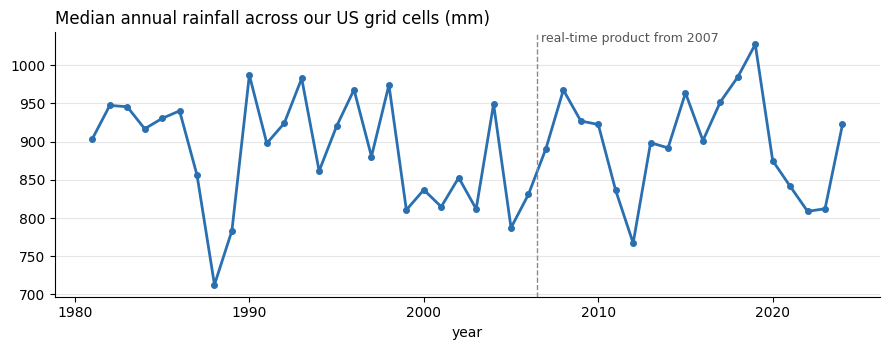

mean of the yearly medians: 1981-2006 886 mm, 2007-2013 887 mm, 2014-2024 907 mm


In [9]:
# Step 4.2 Median annual rainfall across our US cells, by year
us_year = annual[annual["source"] == "us"].groupby("year")["annual_mm"].median()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(us_year.index, us_year.values, color="#2a6fb0", linewidth=2, marker="o", markersize=4)
ax.axvline(2006.5, color="#8a8a8a", linewidth=1, linestyle="--")
ax.text(2006.7, ax.get_ylim()[1], "real-time product from 2007", va="top", fontsize=9, color="#555555")
ax.set_title("Median annual rainfall across our US grid cells (mm)", loc="left")
ax.set_xlabel("year"); ax.grid(axis="y", color="#e6e6e6"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(REPORTS / "fig_precip_us_annual_by_year.png", dpi=150); plt.show()
print(f"mean of the yearly medians: 1981-2006 {us_year.loc[1981:2006].mean():.0f} mm, "
      f"2007-2013 {us_year.loc[2007:2013].mean():.0f} mm, 2014-2024 {us_year.loc[2014:2024].mean():.0f} mm")

In [10]:
# Step 4.3 Known places: the Gulf coast should be wet, the desert dry, Hawaii and Puerto Rico from the global grid
places = pd.DataFrame({"place": ["Houston TX", "Miami FL", "New Orleans LA", "Seattle WA", "Phoenix AZ",
                                 "New York NY", "Honolulu HI", "San Juan PR", "Anchorage AK"],
                       "latitude": [29.8, 25.8, 30.0, 47.6, 33.4, 40.7, 21.3, 18.4, 61.2],
                       "longitude": [-95.4, -80.2, -90.1, -122.3, -112.1, -74.0, -157.9, -66.1, -149.9]})
places, _ = map_locations(places, grids, us_max_km=US_MAX_KM, global_max_km=GLOBAL_MAX_KM)   # same rule as Step 2.2
places = places.drop(columns="cell_id").merge(cells[["cell_id", "source", "grid_i", "grid_j"]],
                                              on=["source", "grid_i", "grid_j"], how="left")   # our cell numbers
clim_years = annual[annual["year"].isin(CLIMATE_YEARS)].groupby("cell_id")[["annual_mm", "max1d_mm"]].mean().round(0)
places.merge(clim_years, on="cell_id", how="left")

,place,latitude,longitude,source,grid_i,grid_j,dist_km,cell_id,annual_mm,max1d_mm
0,Houston TX,29.8,-95.4,us,39,138,8.7,575,1276.0,98.0
1,Miami FL,25.8,-80.2,us,23,199,11.2,185,1524.0,89.0
2,New Orleans LA,30.0,-90.1,us,40,159,14.1,659,1515.0,106.0
3,Seattle WA,47.6,-122.3,us,110,30,6.3,9417,997.0,50.0
4,Phoenix AZ,33.4,-112.1,us,53,71,3.6,1885,211.0,26.0
5,New York NY,40.7,-74.0,us,82,224,13.4,5936,1134.0,65.0
6,Honolulu HI,21.3,-157.9,global,137,404,16.5,135,910.0,79.0
7,San Juan PR,18.4,-66.1,global,143,587,23.0,152,1247.0,69.0
8,Anchorage AK,61.2,-149.9,global,57,420,9.8,46,572.0,25.0


In [11]:
# Step 4.4 Harvey: the wettest 3 days in Houston's cell in August-September 2017
z = np.load(WORK / "cells" / "2017.npz")
houston = int(places.loc[places["place"] == "Houston TX", "cell_id"].iloc[0])
s = pd.Series(z["x"][:, houston], index=pd.to_datetime(z["dates"]))
s3 = s.rolling(3).sum()
print("wettest day:", s.idxmax().date(), round(s.max()), "mm; wettest 3 days ending", s3.idxmax().date(), round(s3.max()), "mm")
s.loc["2017-08-20":"2017-09-05"].round(1).to_frame("rain_mm").T

wettest day: 2017-08-27 314 mm; wettest 3 days ending 2017-08-29 723 mm


,2017-08-20,2017-08-21,2017-08-22,2017-08-23,2017-08-24,2017-08-25,2017-08-26,2017-08-27,2017-08-28,2017-08-29,2017-08-30,2017-08-31,2017-09-01,2017-09-02,2017-09-03,2017-09-04,2017-09-05
rain_mm,0.0,0.0,0.0,0.0,2.2,0.0,42.400002,313.899994,234.5,174.5,23.0,0.0,0.8,0.0,0.0,0.0,0.0


### Section 5. Static features

#### 5.1 Climatology per cell (1981–2013)
- `precip_annual_mean_mm`: the average annual total
- `precip_max1d_mean_mm`: the average of each year's wettest day
- `precip_100yr_1d_mm`: the 1-day rainfall expected once in 100 years, from a GEV distribution fitted to the annual maxima by L-moments:

$$x_{100} = \mu + \frac{\sigma}{\xi}\left[\left(-\ln\left(1 - \tfrac{1}{100}\right)\right)^{-\xi} - 1\right]$$

where $\mu$ is the location, $\sigma$ the scale and $\xi$ the shape ($\xi > 0$ = heavy upper tail). A cell with fewer than 20 complete years gets NULL.

In [12]:
# Step 5.1 Static features, saved for notebook 05
climate = climate_summary(annual[annual["year"].isin(CLIMATE_YEARS)], return_period=RETURN_PERIOD, min_years=MIN_YEARS)
climate = cells.merge(climate, on="cell_id", how="left")
climate.to_parquet(PROCESSED / "precip_climate.parquet", index=False)
print(f"saved precip_climate.parquet: {len(climate):,} cells; without values: {climate['precip_100yr_1d_mm'].isna().sum():,}")
climate.groupby("source")[["precip_annual_mean_mm", "precip_max1d_mean_mm", "precip_100yr_1d_mm", "gev_shape"]].describe().T.round(1)

saved precip_climate.parquet: 9,853 cells; without values: 0


source                       global      us
precip_annual_mean_mm count   171.0  9682.0
                      mean    974.9   892.8
                      std     757.2   386.9
                      min     115.0    74.4
                      25%     470.4   573.1
                      50%     735.3   914.9
                      75%    1232.8  1178.3
                      max    4466.6  3132.8
precip_max1d_mean_mm  count   171.0  9682.0
                      mean     55.6    55.5
                      std      42.0    21.1
                      min      12.8    12.6
                      25%      28.1    41.2
                      50%      43.8    55.3
                      75%      65.7    70.7
                      max     247.9   129.8
precip_100yr_1d_mm    count   171.0  9682.0
                      mean    210.6   127.1
                      std     287.6    56.0
                      min      32.8    23.6
                      25%      71.8    85.7
                      50%     128.3   123.6
                      75%     196.2   160.9
                      max    1564.8   534.2
gev_shape             count   171.0  9682.0
                      mean      0.2     0.1
                      std       0.2     0.1
                      min      -0.3    -0.5
                      25%       0.0    -0.0
                      50%       0.2     0.1
                      75%       0.3     0.2
                      max       0.8     0.7

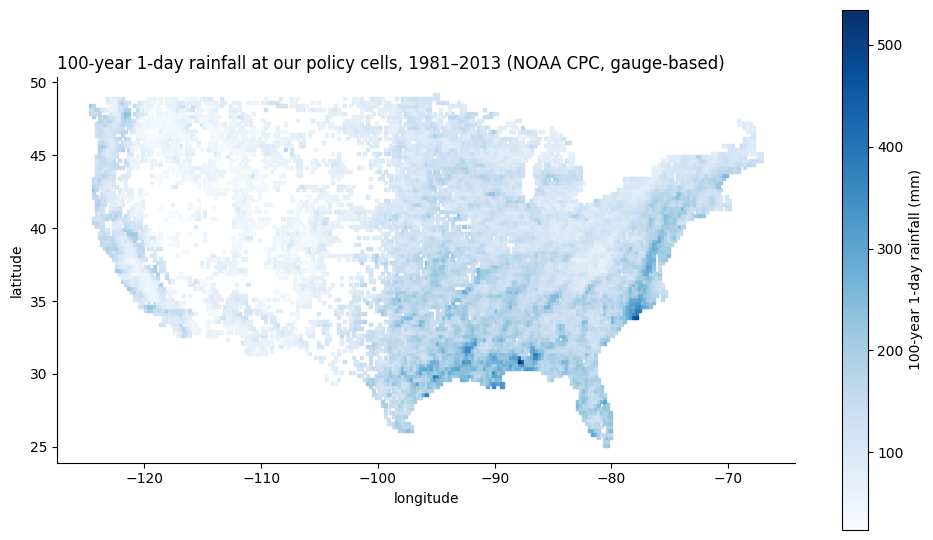

In [13]:
# Step 5.2 Map of the 100-year 1-day rainfall (mainland US)
main = climate[(climate["source"] == "us")]
fig, ax = plt.subplots(figsize=(10, 5.5))
pts = ax.scatter(main["cell_lon"], main["cell_lat"], c=main["precip_100yr_1d_mm"], s=5, cmap="Blues", marker="s")
fig.colorbar(pts, ax=ax, label="100-year 1-day rainfall (mm)")
ax.set_title("100-year 1-day rainfall at our policy cells, 1981–2013 (NOAA CPC, gauge-based)", loc="left")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_aspect(1.25)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(REPORTS / "fig_precip_100yr_map.png", dpi=150); plt.show()

### Section 6. Dated features

#### 6.1 Windows before every start date
For every cell and every day from the first to the last start date, we compute the rain in windows that end **the day before**:

| Feature | Window |
|---|---|
| `precip_90d_mm` | total of the last 90 days |
| `precip_365d_pct_normal` | total of the last 365 days, as % of the cell's `precip_annual_mean_mm` |
| `precip_max1d_365d_mm` | wettest single day of the last 365 days |
| `precip_max3d_365d_mm` | wettest 3 consecutive days of the last 365 days |
| `heavy_rain_days_3y` | days with 50+ mm in the last 3 years |

A window with more than 10% missing days gets NULL; small gaps are filled pro rata in the totals. We also save `precip_365d_mm` (for the EDA) and `precip_last_day` (for the leakage check); neither is a feature. One file per start year.

In [14]:
# Step 6.1 Dated features, one file per start year
t0 = time.time()
z = [np.load(WORK / "cells" / f"{y}.npz") for y in DAILY_YEARS]
dates = np.concatenate([a["dates"] for a in z]); x = np.concatenate([a["x"] for a in z]); del z
assert np.all(np.diff(dates) == np.timedelta64(1, "D")), "a day is missing between years"
annual_mean = climate.set_index("cell_id").reindex(cells["cell_id"])["precip_annual_mean_mm"].to_numpy()
for year, frame in dated_windows(dates, x, annual_mean, START_FROM, START_TO):
    save_daily(frame, DAILY_OUT / f"{year}.parquet")
    print(f"{year}: {len(frame):,} rows")
del x
print(f"done in {(time.time() - t0) / 60:.1f} min")

2014: 3,596,345 rows
2015: 3,596,345 rows
2016: 3,606,198 rows
2017: 3,596,345 rows
2018: 3,596,345 rows
2019: 3,596,345 rows
2020: 3,606,198 rows
2021: 3,596,345 rows
2022: 3,596,345 rows
2023: 3,596,345 rows
2024: 2,404,132 rows
done in 0.3 min


In [15]:
# Step 6.2 Checks: one row per cell and day, windows end before the start, share of NULLs
chk = con.sql(f'''
    SELECT COUNT(*) AS rows, COUNT(DISTINCT cell_id) AS cells, COUNT(DISTINCT period_start) AS start_days,
           MIN(period_start) AS first_start, MAX(period_start) AS last_start,
           COUNT(*) FILTER (WHERE precip_last_day >= period_start) AS windows_on_or_after_start,
           ROUND(100 * AVG(CASE WHEN precip_90d_mm IS NULL THEN 1 ELSE 0 END), 2) AS pct_null_90d,
           ROUND(100 * AVG(CASE WHEN heavy_rain_days_3y IS NULL THEN 1 ELSE 0 END), 2) AS pct_null_3y
    FROM read_parquet('{DAILY_OUT}/*.parquet')
''').df()
chk["rows_ok"] = chk["rows"] == chk["cells"] * chk["start_days"]
chk.T

,0
rows,38387288
cells,9853
start_days,3896
first_start,2014-01-01 00:00:00
last_start,2024-08-31 00:00:00
windows_on_or_after_start,0
pct_null_90d,0.03
pct_null_3y,0.03
rows_ok,True


In [16]:
# Step 6.3 Harvey from the policy's side: Houston's dated features for starts around the storm
con.sql(f'''
    SELECT period_start, precip_last_day, ROUND(precip_90d_mm) AS rain_90d, ROUND(precip_365d_pct_normal) AS pct_normal,
           ROUND(precip_max1d_365d_mm) AS wettest_day, ROUND(precip_max3d_365d_mm) AS wettest_3d, heavy_rain_days_3y
    FROM read_parquet('{DAILY_OUT}/2017.parquet')
    WHERE cell_id = {houston} AND period_start BETWEEN DATE '2017-08-23' AND DATE '2017-09-02'
    ORDER BY period_start
''').df()

,period_start,precip_last_day,rain_90d,pct_normal,wettest_day,wettest_3d,heavy_rain_days_3y
0,2017-08-23,2017-08-22,469.0,97.0,108.0,125.0,17.0
1,2017-08-24,2017-08-23,469.0,96.0,108.0,125.0,17.0
2,2017-08-25,2017-08-24,471.0,96.0,108.0,125.0,17.0
3,2017-08-26,2017-08-25,471.0,96.0,108.0,125.0,17.0
4,2017-08-27,2017-08-26,514.0,99.0,108.0,125.0,17.0
5,2017-08-28,2017-08-27,792.0,123.0,314.0,356.0,18.0
6,2017-08-29,2017-08-28,1026.0,142.0,314.0,591.0,19.0
7,2017-08-30,2017-08-29,1200.0,155.0,314.0,723.0,20.0
8,2017-08-31,2017-08-30,1218.0,156.0,314.0,723.0,20.0
9,2017-09-01,2017-08-31,1215.0,156.0,314.0,723.0,20.0


> **Our findings:** _(Are the files complete? Does 2007 show a jump? Do the known places look right: Gulf coast wet, Phoenix dry? Does Harvey appear in Houston, and only for starts after the rain? How many locations have no cell, and where?)_

#### 6.4 Limitations
- **Gauge density.** CPC interpolates rain gauges, so areas with few gauges (mountains, some islands) are smoother than reality, and the real-time product from 2007 uses fewer gauges (Step 4.2).
- **Coarse grid.** 0.25° (about 28 km) on the mainland and 0.5° elsewhere: the features describe the area, not the street. Local risk comes from the flood zone, elevation and Risk Rating 2.0.
- **Day boundary.** A CPC day runs from 12:00 to 12:00 UTC, which doesn't matter for windows of 90 days or more.
- **Future work.** Climate scenarios (e.g. NEX-GDDP-CMIP6 SSP projections) could stress-test the trained model under a changed climate. They are not model features.